# Clothes Recommendation Based on VGG19 Classifier


we can compute similarities between the different products using the previously extracted image features which were obtained in chapter.2 VGG19 report.



## 0. imports and parameters setup

In [ ]:
# imports
import keras
from keras.applications.vgg19 import VGG19
from keras.preprocessing.image import load_img,img_to_array
from keras.models import Model
from keras.applications.imagenet_utils import preprocess_input

from PIL import Image
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial import distance
import pandas as pd

import cv2

In [ ]:
# parameters setup
import tensorflow as tf
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

imgs_model_width, imgs_model_height = 32 , 32

nb_closest_images = 5 # number of most similar images to retrieve
print(x_train.shape)

(60000, 28, 28)


In [ ]:
#resize
def resize(img_array):
    tmp = np.empty((img_array.shape[0], 32, 32))

    for i in range(len(img_array)):
        img = img_array[i].reshape(28, 28).astype('uint8')
        img = cv2.resize(img, (32, 32))
        img = img.astype('float32')/255
       # img = np.expand_dims(img, axis=0)
        tmp[i] = img
    return tmp

x_train_rs = resize(x_train)
print("train x shape:", x_train_rs.shape)
x_test_rs = resize(x_test)
print("test x shape:", x_test_rs.shape)

train x shape: (60000, 32, 32)
test x shape: (10000, 32, 32)


In [ ]:
x_train_fin = np.stack((x_train_rs,)*3, axis=-1)
print("x train shape:", x_train_fin.shape)
x_test_fin = np.stack((x_test_rs,)*3, axis=-1)
print("x test shape:", x_test_fin.shape)

x train shape: (60000, 32, 32, 3)
x test shape: (10000, 32, 32, 3)


## 1. VGG Model Redesign


In [ ]:

#Q = 1000
#x_train_fin1=x_train_fin[0:Q,:]

#vgg_model_SI = VGG19(weights='imagenet', include_top = False, input_shape=(32, 32, 3))
#for layer in base_model.layers:
#    layer.trainable = False
#myinput = Input(shape=(224,224,3))
#base_model = base_model(myinput)
#SIact = Model(inputs=vgg_model_SI.input, outputs=vgg_model_SI.layers[-1].output)
#activeSI = Model(inputs = myinput, outputs = base_model)
#activeSI = SIact.predict(x_train_fin1)
 #print(activeSI.shape)

 #OK WHAT NOW??????

#y_train1=y_train[0:Q,:]
#M=np.zeros((Q,Q))
#M=M.astype('float32')
#si=0
#p=np.eye(Q)*200000
#x_test_fin1=activeSI.reshape(Q,268203)
#C=x_test_fin1.dot(x_test_fin1.T)
#print(C)

#for i in range(Q):
#    for j in range(Q):
#        M[i,j]=C[i,i]
#D1=np.add(M,M.T)
#D=np.subtract(D1,2*C)
#D=np.add(D,p)
#for i in range(Q):

#    minp = np.argmin(D[i,:])
#    if np.subtract(y_train1[i],y_train1[minp])==0:
#        si +=1
#SI=si/Q
#print(SI)

In [ ]:
# loading the model
vgg_model = VGG19(weights='imagenet', include_top = False, input_shape=(32, 32, 3))

# removing the last two layers in order to get features instead of predictions
feat_extractor = Model(inputs=vgg_model.input, outputs=vgg_model.layers[-1].output)
#vgg_model.summary()
feat_extractor.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 32, 32, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 32, 32, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 16, 16, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 16, 16, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 16, 16, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 8, 8, 128)         0   

## 2. feeding one source image into the CNN

In [ ]:
image_batch = np.expand_dims(x_train_fin[10], axis=0)
print('image batch size', image_batch.shape)

# prepare the image for the VGG model
processed_image = preprocess_input(image_batch.copy())

image batch size (1, 32, 32, 3)


In [ ]:
# get the extracted features
img_features = feat_extractor.predict(processed_image)

print("features successfully extracted!")
print("number of image features:",img_features.size)
img_features.shape

features successfully extracted!
number of image features: 512


(1, 1, 1, 512)

## 3. feeding the whole dataset into the CNN



In [ ]:
#load all the images and prepare them for feeding into the CNN

importedImages = []

#for f in files:
for i in range(len(x_test_fin)):
    image_batch = np.expand_dims(x_test_fin[i], axis=0)
    importedImages.append(image_batch)

images = np.vstack(importedImages)
processed_imgs = preprocess_input(images.copy())

In [ ]:
#extract the images features

imgs_features = feat_extractor.predict(processed_imgs)

print("features successfully extracted!")
#imgs_features.shape
imgs_features.shape

features successfully extracted!


(10000, 1, 1, 512)

# 4. computing the cosine similarity metrics



In [ ]:
def calculate_CosSim(imgs_features, index):
    imgs_features_vector = imgs_features.reshape((imgs_features.shape[0], imgs_features.shape[1]*imgs_features.shape[2]*imgs_features.shape[3]))
    img_features_vector = imgs_features[index].reshape((1, imgs_features[index].shape[0]*imgs_features[index].shape[1]*imgs_features[index].shape[2]))
    #print(imgs_features_vector.shape, img_features_vector.shape)

    cosSimilarities = cosine_similarity(imgs_features_vector, img_features_vector)
    #print(cosSimilarities.shape)
    # store the results into a pandas dataframe

    cos_similarities_df = pd.DataFrame(cosSimilarities, index=[x for x in range(imgs_features_vector.shape[0])], columns=[index])
    #print(cos_similarities_df.head())
    return cos_similarities_df

In [ ]:
def calculate_EucDist(imgs_features, index):
  imgs_features_vector = imgs_features.reshape((imgs_features.shape[0], imgs_features.shape[1]*imgs_features.shape[2]*imgs_features.shape[3]))
  img_features_vector = imgs_features[index].reshape((1, imgs_features[index].shape[0]*imgs_features[index].shape[1]*imgs_features[index].shape[2]))

  EucDistance = []
#print(imgs_features_vector.shape, img_features_vector.shape)
  for i in range(len(imgs_features_vector)):
    EucDist = distance.euclidean(imgs_features_vector[i], img_features_vector)
    distances = np.expand_dims(EucDist, axis=0)
    EucDistance.append(distances)

  dataEuc = np.vstack(EucDistance)


#print(dataEuc.shape)
    # store the results into a pandas dataframe

  euc_dist_df = pd.DataFrame(dataEuc, index=[x for x in range(imgs_features_vector.shape[0])], columns=[index])
    # print(cos_similarities_df.head())
  return euc_dist_df

In [ ]:
calculate_CosSim(imgs_features, 2)
data = calculate_CosSim(imgs_features, 2)

In [ ]:
calculate_EucDist(imgs_features, 2)
dataplotEuc= calculate_EucDist(imgs_features, 2)

In [ ]:
# function to retrieve the most similar products for a given one with COSINE SIMILARITY

def retrieve_most_similar_products(images, index):

    print("-----------------------------------------------------------------------")
    print("original product:")

    plt.imshow(images[index])
    plt.show()

    print("-----------------------------------------------------------------------")
    print("most similar products:")


    cos_similarities_df = calculate_CosSim(imgs_features, index)

    closest_imgs = cos_similarities_df.sort_values(by= index, ascending=False)[1:nb_closest_images+1].index
    #closest_imgs = cos_similarities_df.sort_values(by= index, ascending=False)[1:29+1].index
    #closest_imgs_scores = cos_similarities_df.sort_values(by = index, ascending=False)[1:29+1]
    closest_imgs_scores = cos_similarities_df.sort_values(by = index, ascending=False)[1:nb_closest_images+1]

    print(closest_imgs_scores)

NameError: ignored

# 5. recommending most similar products



In [ ]:
# function to retrieve the most similar products for a given one with COSINE SIMILARITY

def retrieve_most_similar_products(images, index):

    print("-----------------------------------------------------------------------")
    print("original product:")

    plt.imshow(images[index])
    plt.show()

    print("-----------------------------------------------------------------------")
    print("most similar products:")


    cos_similarities_df = calculate_CosSim(imgs_features, index)

    closest_imgs = cos_similarities_df.sort_values(by= index, ascending=False)[1:nb_closest_images+1].index
    #closest_imgs = cos_similarities_df.sort_values(by= index, ascending=False)[1:29+1].index
    #closest_imgs_scores = cos_similarities_df.sort_values(by = index, ascending=False)[1:29+1]
    closest_imgs_scores = cos_similarities_df.sort_values(by = index, ascending=False)[1:nb_closest_images+1]

print(closest_imgs_scores)

    plt.figure(figsize=(15, 7))
    for i in range(0,len(closest_imgs)):
        plt.subplot(1, nb_closest_images, i+1)
        plt.imshow(x_test_fin[closest_imgs[i]])
    plt.show()
    #print("similarity score : ",closest_imgs_scores[i])

In [ ]:
# function to retrieve the most similar products for a given one with COSINE SIMILARITY

def retrieve_most_similar_products_Euc(images, index):

    print("-----------------------------------------------------------------------")
    print("original product:")

    plt.imshow(images[index])
    plt.show()

    print("-----------------------------------------------------------------------")
    print("most similar products:")


    euc_dist_df = calculate_EucDist(imgs_features, index)

    closest_imgs = euc_dist_df.sort_values(by= index, ascending=True)[1:nb_closest_images+1].index
    #closest_imgs = cos_similarities_df.sort_values(by= index, ascending=False)[1:29+1].index
    #closest_imgs_scores = cos_similarities_df.sort_values(by = index, ascending=False)[1:29+1]
    closest_imgs_scores = euc_dist_df.sort_values(by = index, ascending=True)[1:nb_closest_images+1]

#print(closest_imgs_scores)

    plt.figure(figsize=(15, 7))
    for i in range(0,len(closest_imgs)):
        plt.subplot(1, nb_closest_images, i+1)
        plt.imshow(x_test_fin[closest_imgs[i]])
    plt.show()
    #print("similarity score : ",closest_imgs_scores[i])

-----------------------------------------------------------------------
original product:


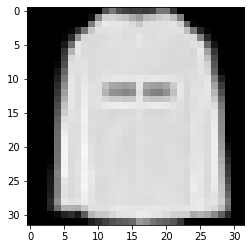

-----------------------------------------------------------------------
most similar products:


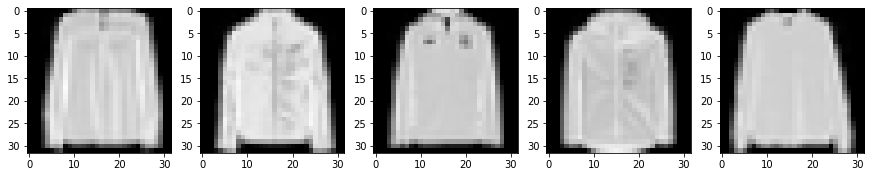

-----------------------------------------------------------------------
original product:


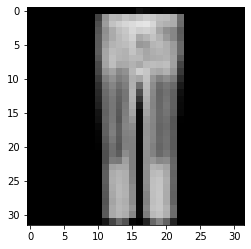

-----------------------------------------------------------------------
most similar products:


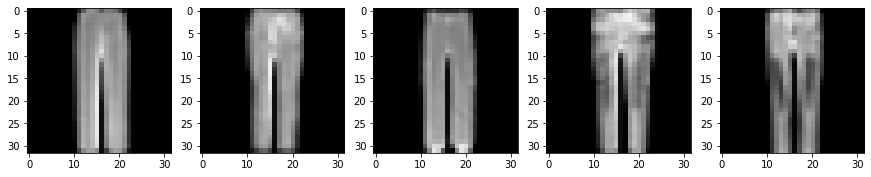

-----------------------------------------------------------------------
original product:


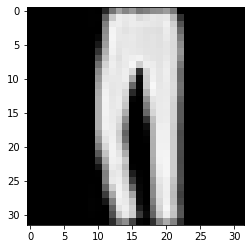

-----------------------------------------------------------------------
most similar products:


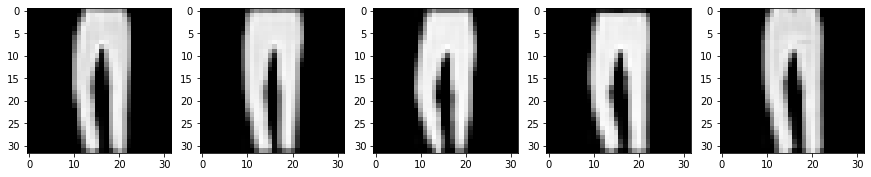

-----------------------------------------------------------------------
original product:


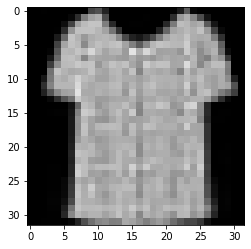

-----------------------------------------------------------------------
most similar products:


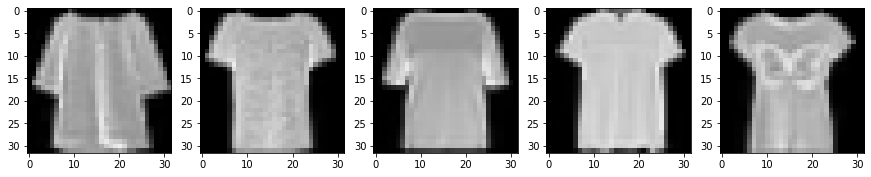

In [ ]:
for index in [98, 15, 2, 1000]:
    retrieve_most_similar_products(x_test_fin, index)

-----------------------------------------------------------------------
original product:


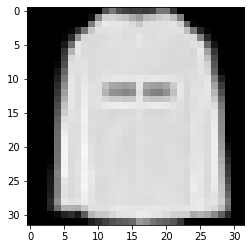

-----------------------------------------------------------------------
most similar products:


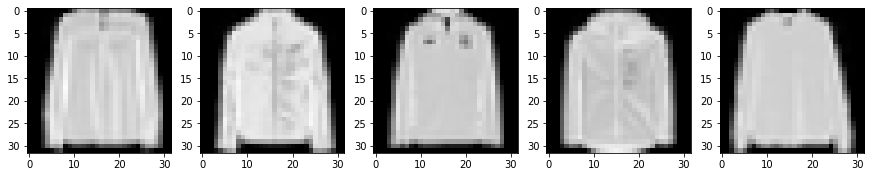

-----------------------------------------------------------------------
original product:


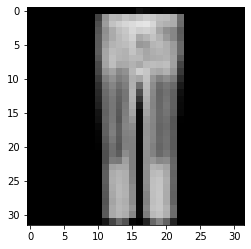

-----------------------------------------------------------------------
most similar products:


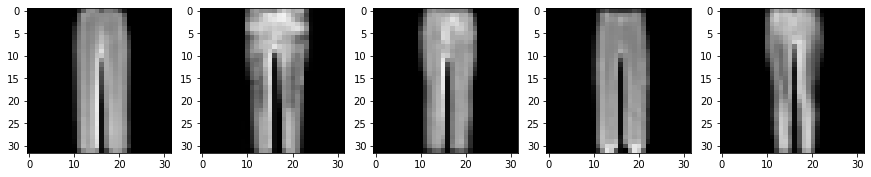

-----------------------------------------------------------------------
original product:


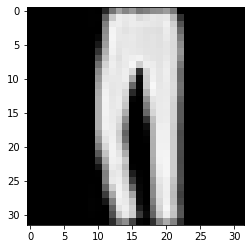

-----------------------------------------------------------------------
most similar products:


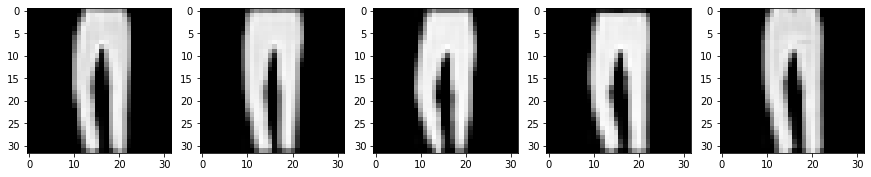

-----------------------------------------------------------------------
original product:


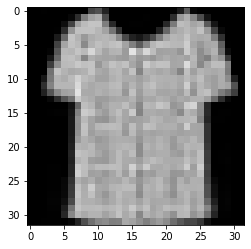

-----------------------------------------------------------------------
most similar products:


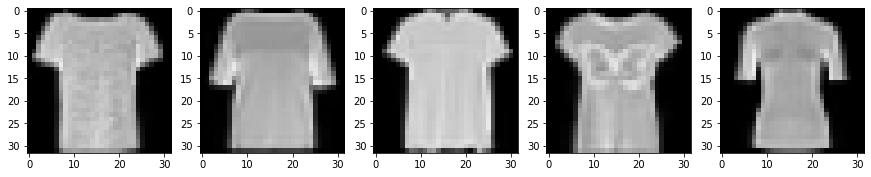

In [ ]:
for index in [98, 15, 2, 1000]:
    retrieve_most_similar_products_Euc(x_test_fin, index)

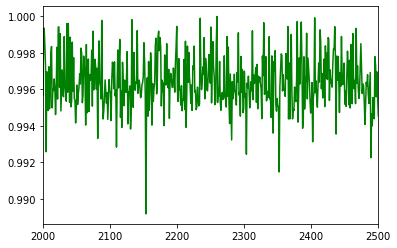

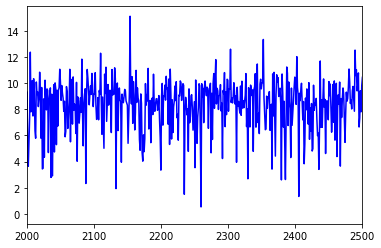

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


#cos_similarities_df.plot(kind='scatter',x=cos_similarities_df. iloc[:, 0] ,y=cos_similarities_df. iloc[0, :],color='red')
plt.plot(data, label = 'cosine similarity rates', color = 'green')
plt.xlim([2000, 2500])
plt.show()

plt.plot(dataplotEuc, label = 'cosine similarity rates', color = 'blue')
plt.xlim([2000, 2500])
plt.show()